# UNIT 4 — Hidden Markov Model
## "What stage of an attack is happening right now, when we can only see the events it leaves behind?"

In [ ]:
import pandas as pd                      # for working with tables
import numpy as np                       # for numbers and random values
import matplotlib.pyplot as plt          # for charts

from sklearn.metrics import accuracy_score, confusion_matrix

print("Ready.")

Ready.


In [ ]:
column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]

# If the download ever fails: download KDDTrain+.txt and KDDTest+.txt from
# https://www.unb.ca/cic/datasets/nsl.html , upload them with the folder icon on the left,
# and write their names here, like {"train": "KDDTrain+.txt", "test": "KDDTest+.txt"}
LOCAL_FILES = {"train": None, "test": None}

base = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/"
web_links = {
    "train": [base + "KDDTrain%2B.txt", base + "KDDTrain+.txt"],
    "test":  [base + "KDDTest%2B.txt",  base + "KDDTest+.txt"],
}

def load_nsl(which):
    places = ([LOCAL_FILES[which]] if LOCAL_FILES[which] else []) + web_links[which]
    for place in places:
        try:
            df = pd.read_csv(place, header=None, names=column_names)
            if len(df) > 1000 and df.shape[1] == 43:
                print(f"{which:<5}: {len(df):,} rows loaded")
                return df
        except Exception:
            pass          # that place did not work, try the next one
    raise RuntimeError("Could not load the " + which + " file. See the note above this cell.")

train_data = load_nsl("train")     # KDDTrain+  -> used to LEARN the model
test_data  = load_nsl("test")      # KDDTest+   -> used to TEST it (has attack types never seen in training)

train: 125,973 rows loaded
test : 22,544 rows loaded


In [ ]:
# Group the attack names into families. Each family will play the role of one STAGE of an attack.
# (KDDTest+ has extra attack names that KDDTrain+ does not, so they are listed here too.)
family_of = {
    "normal": "normal",
    # probing: scanning the network to find weak spots
    "satan": "probe", "ipsweep": "probe", "nmap": "probe", "portsweep": "probe",
    "mscan": "probe", "saint": "probe",
    # remote-to-local: getting in from outside (guessing passwords, uploading files)
    "guess_passwd": "r2l", "ftp_write": "r2l", "imap": "r2l", "phf": "r2l",
    "multihop": "r2l", "warezmaster": "r2l", "warezclient": "r2l", "spy": "r2l",
    "xlock": "r2l", "xsnoop": "r2l", "snmpguess": "r2l", "snmpgetattack": "r2l",
    "httptunnel": "r2l", "sendmail": "r2l", "named": "r2l",
    # user-to-root: an attacker who is already inside takes full control
    "buffer_overflow": "u2r", "loadmodule": "u2r", "rootkit": "u2r", "perl": "u2r",
    "sqlattack": "u2r", "xterm": "u2r", "ps": "u2r",
}

for df in (train_data, test_data):
    df["label"] = df["label"].str.strip()
    df["family"] = df["label"].map(family_of)

# DoS attacks (neptune, smurf, ...) do not belong to a multi-step break-in, so we leave them out.
train_data = train_data[train_data["family"].notna()].reset_index(drop=True)
test_data  = test_data[test_data["family"].notna()].reset_index(drop=True)

pd.DataFrame({"KDDTrain+": train_data["family"].value_counts(),
              "KDDTest+":  test_data["family"].value_counts()})

,KDDTrain+,KDDTest+
family,,
normal,67343,9711
probe,11656,2421
r2l,995,2885
u2r,52,67


In [ ]:
def add_events(df):
    """Give every connection ONE event name, using simple rules on its real columns."""
    rules = [
        ((df["root_shell"] > 0) | (df["su_attempted"] > 0) |
         (df["num_root"] > 0) | (df["num_shells"] > 0),                         "ROOT_ACTIVITY"),
        (df["num_failed_logins"] > 0,                                           "FAILED_LOGIN"),
        ((df["num_file_creations"] > 0) | (df["num_access_files"] > 0) |
         (df["hot"] > 0) | (df["is_guest_login"] > 0),                          "FILE_ACCESS"),
        ((df["serror_rate"] > 0.8) | (df["count"] > 200),                       "FLOOD"),
        ((df["rerror_rate"] > 0.5) | (df["dst_host_diff_srv_rate"] > 0.3) |
         ((df["diff_srv_rate"] > 0.3) & (df["count"] > 1)),                     "SCAN"),
    ]
    df["event"] = np.select([condition for condition, name in rules],
                            [name for condition, name in rules],
                            default="NORMAL_CONN")

add_events(train_data)
add_events(test_data)

event_names = ["NORMAL_CONN", "SCAN", "FLOOD", "FAILED_LOGIN", "FILE_ACCESS", "ROOT_ACTIVITY"]

# What does each family look like through these events? (each row adds up to 100%)
# reindex (not plain indexing) in case some event never happens to occur for any family in this file
train_table = (pd.crosstab(train_data["family"], train_data["event"], normalize="index")
              .reindex(columns=event_names, fill_value=0) * 100).round(1)
test_table  = (pd.crosstab(test_data["family"],  test_data["event"],  normalize="index")
              .reindex(columns=event_names, fill_value=0) * 100).round(1)

print("KDDTrain+ : % of each family's records that produce each event")
print(train_table.to_string())
print()
print("KDDTest+  : the same table on the unseen test file")
print(test_table.to_string())

KDDTrain+ : % of each family's records that produce each event
event   NORMAL_CONN  SCAN  FLOOD  FAILED_LOGIN  FILE_ACCESS  ROOT_ACTIVITY
family                                                                    
normal         82.4  10.5    3.4           0.1          2.5            1.1
probe          43.4  38.3   18.1           0.0          0.1            0.0
r2l            55.2   1.1    0.6           5.2         36.9            1.0
u2r            21.2   5.8    0.0           1.9         13.5           57.7

KDDTest+  : the same table on the unseen test file
event   NORMAL_CONN  SCAN  FLOOD  FAILED_LOGIN  FILE_ACCESS  ROOT_ACTIVITY
family                                                                    
normal         89.6   3.6    5.5           0.1          1.1            0.2
probe          11.2  52.3   36.5           0.0          0.0            0.0
r2l            56.3   8.1    0.1          16.3         18.6            0.7
u2r            22.4   4.5    0.0           1.5         16.4 

In [ ]:
backing = pd.DataFrame({"real records in KDDTrain+": train_data["family"].value_counts(),
                        "real records in KDDTest+":  test_data["family"].value_counts()})
print(backing.to_string())
print()
print("What the 'r2l' (Break-in) records in KDDTrain+ really are:")
print((train_data.loc[train_data["family"] == "r2l", "label"].value_counts(normalize=True).head(4) * 100).round(1).to_string())

        real records in KDDTrain+  real records in KDDTest+
family                                                     
normal                      67343                      9711
probe                       11656                      2421
r2l                           995                      2885
u2r                            52                        67

What the 'r2l' (Break-in) records in KDDTrain+ really are:
label
warezclient     89.4
guess_passwd     5.3
warezmaster      2.0
imap             1.1


In [ ]:
# The 4 HIDDEN stages of our story. The defender never sees these, only the events.
stage_names = ["Normal", "Recon", "Break-in", "Takeover"]
stage_family = {"Normal": "normal", "Recon": "probe", "Break-in": "r2l", "Takeover": "u2r"}

# NOTE: these probabilities are OUR OWN assumptions about how an attack might unfold.
# They are not measured from NSL-KDD and they are not from a published study.
# How an attacker moves between stages from one step to the next (we decide this, it is the "story").
# Row = stage now, column = stage next. Every row adds up to 1.
true_transitions = np.array([
    [0.94, 0.04, 0.02, 0.00],    # Normal   -> mostly stays normal, sometimes recon or a direct break-in
    [0.10, 0.80, 0.10, 0.00],    # Recon    -> keeps scanning, gives up, or moves to break-in
    [0.05, 0.00, 0.80, 0.15],    # Break-in -> keeps trying, gives up, or takes over
    [0.10, 0.00, 0.00, 0.90],    # Takeover -> usually stays in control
])

pd.DataFrame(true_transitions, index=stage_names, columns=stage_names)

,Normal,Recon,Break-in,Takeover
Normal,0.94,0.04,0.02,0.00
Recon,0.10,0.80,0.10,0.00
Break-in,0.05,0.00,0.80,0.15
Takeover,0.10,0.00,0.00,0.90


In [ ]:
random = np.random.default_rng(42)

K = len(stage_names)       # number of hidden stages
M = len(event_names)       # number of different events we can observe

# For every stage, collect the REAL events that connections of that family produced.
event_index = {name: i for i, name in enumerate(event_names)}

def build_pool(df):
    return {stage: df.loc[df["family"] == stage_family[stage], "event"].map(event_index).to_numpy()
            for stage in stage_names}

train_pool = build_pool(train_data)     # real events from KDDTrain+
test_pool  = build_pool(test_data)      # real events from KDDTest+

def make_sequence(pool, length=40):
    """Walk through the hidden stages; at every step draw one real event from that stage."""
    stage = 0                                    # every sequence starts as Normal
    stages, events = [], []
    for _ in range(length):
        stage_pool = pool[stage_names[stage]]
        events.append(stage_pool[random.integers(len(stage_pool))])
        stages.append(stage)
        stage = random.choice(K, p=true_transitions[stage])
    return np.array(stages), np.array(events)

def make_benign_sequence(pool, length=40):
    """A sequence where nothing is wrong: every step is Normal."""
    stage_pool = pool["Normal"]
    events = stage_pool[random.integers(len(stage_pool), size=length)]
    return np.zeros(length, dtype=int), events

train_sequences  = [make_sequence(train_pool) for _ in range(200)]     # learn from these
test_sequences   = [make_sequence(test_pool)  for _ in range(200)]     # judge on these
benign_sequences = [make_benign_sequence(test_pool) for _ in range(100)]

print("Training sequences (from KDDTrain+)    :", len(train_sequences))
print("Test sequences (from KDDTest+)         :", len(test_sequences))
print("Benign-only sequences (from KDDTest+)  :", len(benign_sequences))
print("Events per sequence                    :", len(train_sequences[0][0]))
print()

# show one training sequence that contains an attack
example_stages, example_events = next(s for s in train_sequences if s[0].max() >= 2)
pd.DataFrame({
    "step": range(len(example_stages)),
    "hidden stage (we cannot see)": [stage_names[s] for s in example_stages],
    "event (we CAN see)": [event_names[e] for e in example_events],
}).head(20)

Training sequences (from KDDTrain+)    : 200
Test sequences (from KDDTest+)         : 200
Benign-only sequences (from KDDTest+)  : 100
Events per sequence                    : 40



,step,hidden stage (we cannot see),event (we CAN see)
0,0,Normal,NORMAL_CONN
1,1,Normal,SCAN
2,2,Normal,NORMAL_CONN
3,3,Normal,SCAN
4,4,Recon,NORMAL_CONN
5,5,Recon,NORMAL_CONN
6,6,Recon,NORMAL_CONN
7,7,Recon,NORMAL_CONN
8,8,Break-in,NORMAL_CONN
9,9,Break-in,FILE_ACCESS


In [ ]:
# An HMM is just three tables:
#   start_prob[s]        how likely a sequence is to START in stage s
#   transition[s, t]     how likely to move from stage s to stage t
#   emission[s, e]       how likely stage s is to produce event e
# We learn them by COUNTING, the same idea as Unit 1. The "+1" makes sure no probability is exactly 0.

start_count = np.ones(K)
transition_count = np.ones((K, K))
emission_count = np.ones((K, M))

for stages, events in train_sequences:
    start_count[stages[0]] += 1
    for now, nxt in zip(stages[:-1], stages[1:]):
        transition_count[now, nxt] += 1
    for stage, event in zip(stages, events):
        emission_count[stage, event] += 1

start_prob = start_count / start_count.sum()
transition = transition_count / transition_count.sum(axis=1, keepdims=True)
emission = emission_count / emission_count.sum(axis=1, keepdims=True)

print("Transition table (learned):")
print(pd.DataFrame(transition, index=stage_names, columns=stage_names).round(3))
print()
print("Emission table (learned): how likely each stage is to produce each event")
print(pd.DataFrame(emission, index=stage_names, columns=event_names).round(3))

# how close did counting get to the story we built the data from?
difference = np.abs(transition - true_transitions).max()
print()
print("Largest gap between the learned and the true transition table:", round(difference, 3))
print("(Small means the counting works. It says nothing about real attackers.)")

Transition table (learned):
          Normal  Recon  Break-in  Takeover
Normal     0.939  0.038     0.023     0.000
Recon      0.081  0.813     0.104     0.001
Break-in   0.047  0.001     0.819     0.133
Takeover   0.094  0.001     0.001     0.904

Emission table (learned): how likely each stage is to produce each event
          NORMAL_CONN   SCAN  FLOOD  FAILED_LOGIN  FILE_ACCESS  ROOT_ACTIVITY
Normal          0.824  0.108  0.034         0.002        0.024          0.008
Recon           0.455  0.383  0.159         0.001        0.001          0.001
Break-in        0.557  0.007  0.008         0.044        0.369          0.015
Takeover        0.214  0.044  0.001         0.014        0.142          0.584

Largest gap between the learned and the true transition table: 0.019
(Small means the counting works. It says nothing about real attackers.)


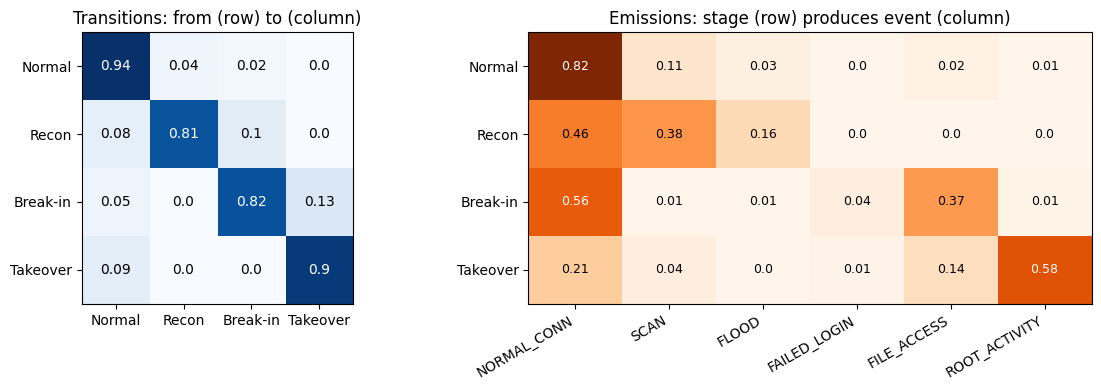

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(transition, cmap="Blues")
axes[0].set_xticks(range(K)); axes[0].set_xticklabels(stage_names)
axes[0].set_yticks(range(K)); axes[0].set_yticklabels(stage_names)
axes[0].set_title("Transitions: from (row) to (column)")
for i in range(K):
    for j in range(K):
        axes[0].text(j, i, round(transition[i, j], 2), ha="center", va="center",
                     color="white" if transition[i, j] > 0.5 else "black")

axes[1].imshow(emission, cmap="Oranges", aspect="auto")
axes[1].set_xticks(range(M)); axes[1].set_xticklabels(event_names, rotation=30, ha="right")
axes[1].set_yticks(range(K)); axes[1].set_yticklabels(stage_names)
axes[1].set_title("Emissions: stage (row) produces event (column)")
for i in range(K):
    for j in range(M):
        axes[1].text(j, i, round(emission[i, j], 2), ha="center", va="center",
                     color="white" if emission[i, j] > 0.5 else "black", fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
def viterbi(events):
    """Find the single most likely chain of hidden stages for a sequence of events."""
    T = len(events)
    log_start, log_trans, log_emit = np.log(start_prob), np.log(transition), np.log(emission)

    best_score = np.zeros((T, K))             # best score of any path that ends in stage s at time t
    came_from = np.zeros((T, K), dtype=int)   # which stage that best path was in one step earlier

    best_score[0] = log_start + log_emit[:, events[0]]
    for t in range(1, T):
        candidates = best_score[t - 1][:, None] + log_trans     # every (previous, current) pair
        came_from[t] = candidates.argmax(axis=0)
        best_score[t] = candidates.max(axis=0) + log_emit[:, events[t]]

    path = [int(best_score[-1].argmax())]     # best last stage, then walk backwards
    for t in range(T - 1, 0, -1):
        path.append(int(came_from[t][path[-1]]))
    return np.array(path[::-1])


def forward_filter(events):
    """After each event: how sure are we about the CURRENT stage, using only events seen so far?"""
    belief = np.zeros((len(events), K))
    now = start_prob * emission[:, events[0]]
    belief[0] = now / now.sum()
    for t in range(1, len(events)):
        now = (belief[t - 1] @ transition) * emission[:, events[t]]
        belief[t] = now / now.sum()
    return belief


# quick check on the example sequence from earlier
print("True stages  :", [stage_names[s][0] for s in example_stages])
print("Viterbi guess:", [stage_names[s][0] for s in viterbi(example_events)])
print("(N = Normal, R = Recon, B = Break-in, T = Takeover)")

True stages  : ['N', 'N', 'N', 'N', 'R', 'R', 'R', 'R', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T']
Viterbi guess: ['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'B', 'B', 'B', 'B', 'B', 'B', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T', 'T']
(N = Normal, R = Recon, B = Break-in, T = Takeover)


In [ ]:
true_all    = np.concatenate([stages for stages, events in test_sequences])
viterbi_all = np.concatenate([viterbi(events) for stages, events in test_sequences])

# Baseline 1: look at each event ALONE and pick the stage most likely to produce it.
alone_guess = emission.argmax(axis=0)
alone_all = np.concatenate([alone_guess[events] for stages, events in test_sequences])

# Baseline 2 (fairer): the same, but also use how common each stage is in the training sequences.
stage_share = np.bincount(np.concatenate([s for s, e in train_sequences]), minlength=K)
stage_share = stage_share / stage_share.sum()
alone_freq_guess = (emission * stage_share[:, None]).argmax(axis=0)
alone_freq_all = np.concatenate([alone_freq_guess[events] for stages, events in test_sequences])

acc_always_normal = (true_all == 0).mean() * 100
acc_viterbi       = accuracy_score(true_all, viterbi_all) * 100
acc_alone         = accuracy_score(true_all, alone_all) * 100
acc_alone_freq    = accuracy_score(true_all, alone_freq_all) * 100

print("Always answering 'Normal'                       :", round(acc_always_normal, 1), "%")
print("Judging each event alone                        :", round(acc_alone, 1), "%")
print("Judging each event alone (+ stage frequency)    :", round(acc_alone_freq, 1), "%")
print("Using the whole sequence (Viterbi)              :", round(acc_viterbi, 1), "%")
print()
print("Stages the fairer baseline ever predicts:", [stage_names[i] for i in sorted(set(alone_freq_guess))])
print()

def recall_table(predicted):
    cm = confusion_matrix(true_all, predicted, labels=range(K))
    return pd.Series(np.diag(cm) / cm.sum(axis=1), index=stage_names)

recall_df = pd.DataFrame({"Viterbi": recall_table(viterbi_all).round(3),
                          "Judged alone": recall_table(alone_all).round(3),
                          "Alone + frequency": recall_table(alone_freq_all).round(3)})
print("Recall = of the steps that really were in this stage, what share did we label correctly?")
recall_df

Always answering 'Normal'                       : 64.4 %
Judging each event alone                        : 79.2 %
Judging each event alone (+ stage frequency)    : 74.3 %
Using the whole sequence (Viterbi)              : 88.9 %

Stages the fairer baseline ever predicts: ['Normal', 'Break-in', 'Takeover']

Recall = of the steps that really were in this stage, what share did we label correctly?


,Viterbi,Judged alone,Alone + frequency
Normal,0.965,0.895,0.989
Recon,0.790,0.880,0.000
Break-in,0.606,0.379,0.379
Takeover,0.856,0.539,0.539


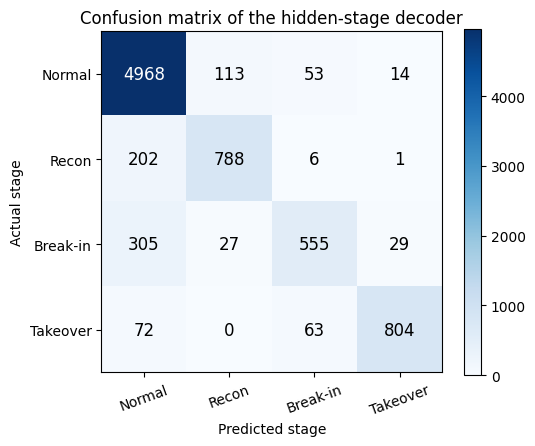

In [ ]:
cm = confusion_matrix(true_all, viterbi_all, labels=range(K))

plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(K), stage_names, rotation=20)
plt.yticks(range(K), stage_names)
plt.xlabel("Predicted stage")
plt.ylabel("Actual stage")
plt.title("Confusion matrix of the hidden-stage decoder")

for i in range(K):
    for j in range(K):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)

plt.colorbar()
plt.show()

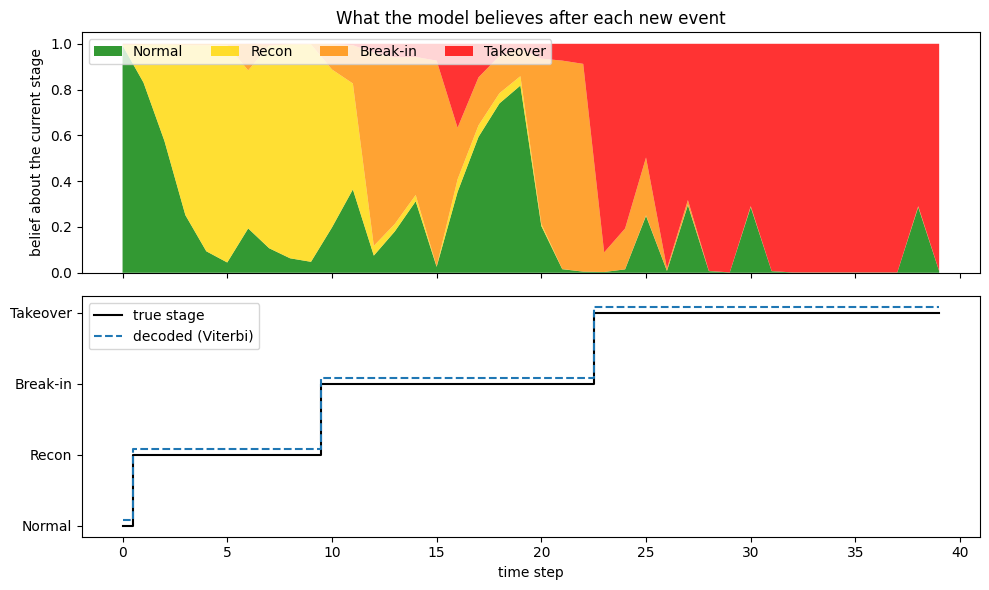

In [ ]:
# Pick the test sequence with the most attack steps and watch the model's belief change over time.
busiest = max(test_sequences, key=lambda s: (s[0] > 0).sum())
busy_stages, busy_events = busiest

belief = forward_filter(busy_events)
decoded = viterbi(busy_events)
steps = np.arange(len(busy_events))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].stackplot(steps, belief.T, labels=stage_names,
                  colors=["green", "gold", "darkorange", "red"], alpha=0.8)
axes[0].set_ylabel("belief about the current stage")
axes[0].set_title("What the model believes after each new event")
axes[0].legend(loc="upper left", ncol=4)

axes[1].step(steps, busy_stages, where="mid", color="black", label="true stage")
axes[1].step(steps, decoded + 0.08, where="mid", color="tab:blue", linestyle="--", label="decoded (Viterbi)")
axes[1].set_yticks(range(K))
axes[1].set_yticklabels(stage_names)
axes[1].set_xlabel("time step")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

In [ ]:
def evaluate_alerts(alert_fn, name):
    hit_steps = attack_steps = false_steps = normal_steps = 0
    delays, detected, n_attack_seqs = [], 0, 0
    before_takeover, n_takeover_seqs = 0, 0

    for stages, events in test_sequences:
        alert = alert_fn(events)
        is_attack = stages > 0
        hit_steps    += (alert & is_attack).sum();   attack_steps += is_attack.sum()
        false_steps  += (alert & ~is_attack).sum();  normal_steps += (~is_attack).sum()

        if is_attack.any():
            n_attack_seqs += 1
            start = int(np.argmax(is_attack))                 # first step that is really an attack
            later_alerts = np.where(alert[start:])[0]         # alerts from that moment on
            first_alert = None
            if len(later_alerts) > 0:
                detected += 1
                delays.append(int(later_alerts[0]))
                first_alert = start + int(later_alerts[0])
            if (stages == 3).any():
                n_takeover_seqs += 1
                takeover_start = int(np.argmax(stages == 3))
                if first_alert is not None and first_alert < takeover_start:
                    before_takeover += 1

    benign_alerted = sum(alert_fn(events).any() for stages, events in benign_sequences)

    return {"method": name,
            "attack steps caught %":             round(hit_steps / attack_steps * 100, 1),
            "false alarms on normal steps %":    round(false_steps / normal_steps * 100, 1),
            "attack sequences detected %":       round(detected / n_attack_seqs * 100, 1),
            "median steps until first alert":    float(np.median(delays)) if delays else np.nan,
            "alerted before Takeover %":         round(before_takeover / max(n_takeover_seqs, 1) * 100, 1),
            "benign sequences with any alert %": round(benign_alerted / len(benign_sequences) * 100, 1)}

rows = []
for threshold in [0.5, 0.8, 0.9]:
    hmm_alert = lambda events, t=threshold: (1 - forward_filter(events)[:, 0]) > t
    rows.append(evaluate_alerts(hmm_alert, f"HMM, alert above {threshold}"))

# the simple rule: alert whenever the event is not NORMAL_CONN
simple_alert = lambda events: events != event_index["NORMAL_CONN"]
rows.append(evaluate_alerts(simple_alert, "simple rule: any odd event"))

alert_table = pd.DataFrame(rows)
alert_table.set_index("method")

,attack steps caught %,false alarms on normal steps %,attack sequences detected %,median steps until first alert,alerted before Takeover %,benign sequences with any alert %
method,,,,,,
"HMM, alert above 0.5",75.4,7.1,96.2,2.0,82.1,46.0
"HMM, alert above 0.8",51.5,1.3,88.6,3.0,67.9,5.0
"HMM, alert above 0.9",41.8,0.5,84.2,4.0,59.8,1.0
simple rule: any odd event,71.0,10.5,98.9,0.0,92.0,99.0


In [ ]:
def run_with_settings(serror_cut, count_cut, rerror_cut, diffsrv_cut, seq_len, n_sequences, seed):
    """Rebuild events, sequences and the HMM from scratch with different choices. Returns test accuracies."""

    def events_for(df):
        rules = [
            ((df["root_shell"] > 0) | (df["su_attempted"] > 0) |
             (df["num_root"] > 0) | (df["num_shells"] > 0),                          "ROOT_ACTIVITY"),
            (df["num_failed_logins"] > 0,                                            "FAILED_LOGIN"),
            ((df["num_file_creations"] > 0) | (df["num_access_files"] > 0) |
             (df["hot"] > 0) | (df["is_guest_login"] > 0),                           "FILE_ACCESS"),
            ((df["serror_rate"] > serror_cut) | (df["count"] > count_cut),           "FLOOD"),
            ((df["rerror_rate"] > rerror_cut) | (df["dst_host_diff_srv_rate"] > diffsrv_cut) |
             ((df["diff_srv_rate"] > diffsrv_cut) & (df["count"] > 1)),              "SCAN"),
        ]
        names = np.select([c for c, n in rules], [n for c, n in rules], default="NORMAL_CONN")
        return pd.Series(names, index=df.index).map(event_index)

    train_events = events_for(train_data)
    test_events  = events_for(test_data)
    pool_train = {s: train_events[train_data["family"] == stage_family[s]].to_numpy() for s in stage_names}
    pool_test  = {s: test_events[test_data["family"] == stage_family[s]].to_numpy() for s in stage_names}

    rng = np.random.default_rng(seed)

    def one_sequence(pool):
        stage, stages, evs = 0, [], []
        for _ in range(seq_len):
            p = pool[stage_names[stage]]
            evs.append(p[rng.integers(len(p))])
            stages.append(stage)
            stage = rng.choice(K, p=true_transitions[stage])
        return np.array(stages), np.array(evs)

    train_seqs = [one_sequence(pool_train) for _ in range(n_sequences)]
    test_seqs  = [one_sequence(pool_test)  for _ in range(n_sequences)]

    # learn the three tables by counting (with the same +1 safety net)
    s_count, t_count, e_count = np.ones(K), np.ones((K, K)), np.ones((K, M))
    for stages, evs in train_seqs:
        s_count[stages[0]] += 1
        for a, b in zip(stages[:-1], stages[1:]):
            t_count[a, b] += 1
        for a, e in zip(stages, evs):
            e_count[a, e] += 1
    s_p = s_count / s_count.sum()
    t_p = t_count / t_count.sum(axis=1, keepdims=True)
    e_p = e_count / e_count.sum(axis=1, keepdims=True)

    def decode(evs):
        T = len(evs)
        ls, lt, le = np.log(s_p), np.log(t_p), np.log(e_p)
        best = np.zeros((T, K)); back = np.zeros((T, K), dtype=int)
        best[0] = ls + le[:, evs[0]]
        for t in range(1, T):
            cand = best[t - 1][:, None] + lt
            back[t] = cand.argmax(axis=0)
            best[t] = cand.max(axis=0) + le[:, evs[t]]
        path = [int(best[-1].argmax())]
        for t in range(T - 1, 0, -1):
            path.append(int(back[t][path[-1]]))
        return np.array(path[::-1])

    truth         = np.concatenate([s for s, e in test_seqs])
    viterbi_guess = np.concatenate([decode(e) for s, e in test_seqs])
    alone_stage   = e_p.argmax(axis=0)
    alone_guess   = np.concatenate([alone_stage[e] for s, e in test_seqs])

    return {"always Normal %": round((truth == 0).mean() * 100, 1),
            "judged alone %":  round(accuracy_score(truth, alone_guess) * 100, 1),
            "Viterbi %":       round(accuracy_score(truth, viterbi_guess) * 100, 1)}


same_rules = dict(serror_cut=0.8, count_cut=200, rerror_cut=0.5, diffsrv_cut=0.3)
settings = {
    "what we used":          dict(**same_rules, seq_len=40, n_sequences=200, seed=42),
    "stricter cut-offs":     dict(serror_cut=0.9, count_cut=300, rerror_cut=0.7, diffsrv_cut=0.5,
                                  seq_len=40, n_sequences=200, seed=42),
    "looser cut-offs":       dict(serror_cut=0.6, count_cut=100, rerror_cut=0.3, diffsrv_cut=0.2,
                                  seq_len=40, n_sequences=200, seed=42),
    "shorter sequences":     dict(**same_rules, seq_len=20, n_sequences=200, seed=42),
    "fewer sequences":       dict(**same_rules, seq_len=40, n_sequences=60,  seed=42),
    "different random seed": dict(**same_rules, seq_len=40, n_sequences=200, seed=7),
}

robustness = pd.DataFrame({name: run_with_settings(**kw) for name, kw in settings.items()}).T
robustness["Viterbi minus alone"] = (robustness["Viterbi %"] - robustness["judged alone %"]).round(1)
robustness

,always Normal %,judged alone %,Viterbi %,Viterbi minus alone
what we used,64.4,79.2,88.9,9.7
stricter cut-offs,64.4,80.2,88.7,8.5
looser cut-offs,64.4,76.8,88.0,11.2
shorter sequences,72.0,82.5,89.9,7.4
fewer sequences,66.4,78.1,88.1,10.0
different random seed,66.6,80.0,91.5,11.5


In [ ]:
def check_sequence(event_list):
    """Give it a list of event names in time order. It prints the most likely hidden stage at every step."""
    events = np.array([event_index[name] for name in event_list])
    path = viterbi(events)
    attack_probability = 1 - forward_filter(events)[-1, 0]

    for t, (name, stage) in enumerate(zip(event_list, path)):
        print(f"step {t:2d}   event: {name:<14} ->  stage: {stage_names[stage]}")

    print()
    print("Chance an attack is under way right now:", round(attack_probability * 100, 1), "%")
    if attack_probability < 0.5:
        print("Suggested action: ALLOW — keep watching")
    elif attack_probability < 0.9:
        print("Suggested action: WATCH CLOSELY — raise the logging level")
    else:
        print("Suggested action: ALERT — treat as an attack in progress")


print("EXAMPLE 1 - ordinary activity, one odd scan-looking event")
check_sequence(["NORMAL_CONN", "NORMAL_CONN", "SCAN", "NORMAL_CONN", "NORMAL_CONN", "NORMAL_CONN"])

print()
print("EXAMPLE 2 - scanning, then failed logins, then file access, then root activity")
check_sequence(["NORMAL_CONN", "SCAN", "SCAN", "FLOOD", "SCAN", "FAILED_LOGIN",
                "FILE_ACCESS", "FILE_ACCESS", "ROOT_ACTIVITY", "ROOT_ACTIVITY"])

EXAMPLE 1 - ordinary activity, one odd scan-looking event
step  0   event: NORMAL_CONN    ->  stage: Normal
step  1   event: NORMAL_CONN    ->  stage: Normal
step  2   event: SCAN           ->  stage: Normal
step  3   event: NORMAL_CONN    ->  stage: Normal
step  4   event: NORMAL_CONN    ->  stage: Normal
step  5   event: NORMAL_CONN    ->  stage: Normal

Chance an attack is under way right now: 9.9 %
Suggested action: ALLOW — keep watching

EXAMPLE 2 - scanning, then failed logins, then file access, then root activity
step  0   event: NORMAL_CONN    ->  stage: Normal
step  1   event: SCAN           ->  stage: Recon
step  2   event: SCAN           ->  stage: Recon
step  3   event: FLOOD          ->  stage: Recon
step  4   event: SCAN           ->  stage: Recon
step  5   event: FAILED_LOGIN   ->  stage: Break-in
step  6   event: FILE_ACCESS    ->  stage: Break-in
step  7   event: FILE_ACCESS    ->  stage: Break-in
step  8   event: ROOT_ACTIVITY  ->  stage: Takeover
step  9   event: ROO

In [ ]:
check_sequence(["NORMAL_CONN",
                "NORMAL_CONN",
                "SCAN",
                "SCAN",
                "NORMAL_CONN",
                "FAILED_LOGIN",
                "NORMAL_CONN",
                "FILE_ACCESS"])

step  0   event: NORMAL_CONN    ->  stage: Normal
step  1   event: NORMAL_CONN    ->  stage: Normal
step  2   event: SCAN           ->  stage: Recon
step  3   event: SCAN           ->  stage: Recon
step  4   event: NORMAL_CONN    ->  stage: Break-in
step  5   event: FAILED_LOGIN   ->  stage: Break-in
step  6   event: NORMAL_CONN    ->  stage: Break-in
step  7   event: FILE_ACCESS    ->  stage: Break-in

Chance an attack is under way right now: 95.3 %
Suggested action: ALERT — treat as an attack in progress


In [ ]:
pd.DataFrame(transition, index=stage_names, columns=stage_names).to_csv("unit4_transition_table.csv")
pd.DataFrame(emission, index=stage_names, columns=event_names).to_csv("unit4_emission_table.csv")
alert_table.to_csv("unit4_alert_comparison.csv", index=False)
recall_df.to_csv("unit4_recall_by_stage.csv")
backing.to_csv("unit4_real_records_per_stage.csv")
robustness.to_csv("unit4_robustness_check.csv")

print("Saved: unit4_transition_table.csv")
print("Saved: unit4_emission_table.csv")
print("Saved: unit4_alert_comparison.csv")
print("Saved: unit4_recall_by_stage.csv")
print("Saved: unit4_real_records_per_stage.csv")
print("Saved: unit4_robustness_check.csv")

Saved: unit4_transition_table.csv
Saved: unit4_emission_table.csv
Saved: unit4_alert_comparison.csv
Saved: unit4_recall_by_stage.csv
Saved: unit4_real_records_per_stage.csv
Saved: unit4_robustness_check.csv


In [ ]:
n_train_steps = sum(len(s) for s, e in train_sequences)
print(f"1. Real events, invented story. Every event comes from a real NSL-KDD record "
      f"(training from KDDTrain+, testing from KDDTest+), but the ORDER of stages and the transition "
      f"probabilities are our own assumption. The model learned from {len(train_sequences)} sequences "
      f"({n_train_steps:,} steps) and was judged on {len(test_sequences)} different sequences. "
      f"Because both come from the same story, the scores are optimistic compared with real traffic.")
print()

print(f"2. Using the whole sequence: Viterbi labels {acc_viterbi:.1f}% of test steps with the right stage. "
      f"Judging each event alone gets {acc_alone:.1f}% ({acc_alone_freq:.1f}% if we also remember how common each stage is). "
      f"Always answering 'Normal' would score {acc_always_normal:.1f}%.")
print()

improved = [s for s in stage_names if recall_df.loc[s, "Viterbi"] > recall_df.loc[s, "Judged alone"]]
worse    = [s for s in stage_names if recall_df.loc[s, "Viterbi"] < recall_df.loc[s, "Judged alone"]]
print("3. Stage by stage (recall, judged alone -> Viterbi):")
for s in stage_names:
    a, b = recall_df.loc[s, "Judged alone"] * 100, recall_df.loc[s, "Viterbi"] * 100
    print(f"     - {s}: {a:.0f}% -> {b:.0f}%")
print(f"   Better with the sequence: {improved if improved else 'none'}.   Worse: {worse if worse else 'none'}.")
print()

if worse:
    print("4. Why a stage can get WORSE with the sequence:")
    for s in worse:
        share_ordinary = emission[stage_names.index(s), event_index["NORMAL_CONN"]] * 100
        print(f"     - {s}: about {share_ordinary:.0f}% of its events look like ordinary connections, and Normal is the "
              f"most common stage, so the decoder leans towards Normal. A sequence model cannot create "
              f"evidence that the events do not contain.")
else:
    print("4. No stage got worse when the whole sequence was used.")
print()

hmm05, simple = alert_table.iloc[0], alert_table.iloc[-1]
better_both = (hmm05["attack steps caught %"] >= simple["attack steps caught %"]
               and hmm05["false alarms on normal steps %"] <= simple["false alarms on normal steps %"])
print(f"5. As an alarm (threshold 0.5): the HMM catches {hmm05['attack steps caught %']}% of attack steps with "
      f"{hmm05['false alarms on normal steps %']}% false alarms on normal steps. The simple rule catches "
      f"{simple['attack steps caught %']}% with {simple['false alarms on normal steps %']}% false alarms. "
      + ("The HMM is better on both counts." if better_both else "Neither is better on both counts, so it is a trade-off."))
print(f"   Detected {hmm05['attack sequences detected %']}% of attacks, a median of "
      f"{hmm05['median steps until first alert']} steps after they began, and gave early warning "
      f"(before Takeover began) in {hmm05['alerted before Takeover %']}% of the attacks that reach Takeover.")
print(f"   On sessions where nothing was wrong, the HMM alarm ever went off in "
      f"{hmm05['benign sequences with any alert %']}% of them. The simple rule: "
      f"{simple['benign sequences with any alert %']}%.")
print()
holds = (robustness["Viterbi minus alone"] > 0).all()
print(f"6. Robustness: under {len(robustness)} different settings (stricter and looser cut-offs, shorter and fewer sequences, "
      f"another random seed) Viterbi's advantage over judging each event alone ranged from "
      f"{robustness['Viterbi minus alone'].min()} to {robustness['Viterbi minus alone'].max()} percentage points. "
      + ("The conclusion held in every case." if holds else
         "It did NOT hold in every case, so say plainly that this result depends on our choices."))
print()
print("   All thresholds:")
print(alert_table[["method", "attack steps caught %", "false alarms on normal steps %",
                   "benign sequences with any alert %"]].to_string(index=False))

1. Real events, invented story. Every event comes from a real NSL-KDD record (training from KDDTrain+, testing from KDDTest+), but the ORDER of stages and the transition probabilities are our own assumption. The model learned from 200 sequences (8,000 steps) and was judged on 200 different sequences. Because both come from the same story, the scores are optimistic compared with real traffic.

2. Using the whole sequence: Viterbi labels 88.9% of test steps with the right stage. Judging each event alone gets 79.2% (74.3% if we also remember how common each stage is). Always answering 'Normal' would score 64.3%.

3. Stage by stage (recall, judged alone -> Viterbi):
     - Normal: 90% -> 96%
     - Recon: 88% -> 79%
     - Break-in: 38% -> 61%
     - Takeover: 54% -> 86%
   Better with the sequence: ['Normal', 'Break-in', 'Takeover'].   Worse: ['Recon'].

4. Why a stage can get WORSE with the sequence:
     - Recon: about 46% of its events look like ordinary connections, and Normal is the 